# Does Qualifying Decide the Race?
### Grid-position impact analysis and finishing-position prediction on Formula 1 data using PySpark

**Big Data Analytics (CSE557), Ramaiah Institute of Technology, 2026**
Team: Arnav Chatterjee, Khuushi Chand Navin · Faculty guide: Uzma Sulthana

This notebook is the working record of the project. Every table, number and chart in it was produced by the code cell directly above it, run on the full Kaggle dataset. It follows the 8 points of the *Dataset Analysis for Real-Time Scenarios* form:

| Form point | Section |
| --- | --- |
| 1. Real-world scenario and problem statement | 1 |
| 2. Recent research paper and existing approach | 2 |
| 3. Objectives and proposed analysis | 3 |
| 4. Dataset identification and preparation | 4 (raw data, cleaning before/after) |
| 5. Big Data implementation and workflow | 5 (Parquet storage, Spark SQL, query plans, window functions, MLlib) |
| 6. Results, visualization and paper comparison | 6 (charts and model comparison) |
| 7. Performance evaluation and observations | 7 (timings, baselines, correctness checks) |
| 8. Tools, responsible use and references | 8 |
| What we changed during development and why | Appendix A |

## 0. Setup
Start a local Spark session and record the environment the results were produced on.

In [1]:
import os, time, platform
import pandas as pd, numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pyspark
from pyspark.sql import SparkSession, Window, functions as F
from IPython.display import Markdown, display
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

DATA = os.environ.get("F1_DATA", "data")                  # folder with the 14 Kaggle CSVs
OUT = os.environ.get("F1_OUT", "notebook_output")          # charts, Parquet files
WRITE_PARQUET = os.environ.get("F1_PARQUET", "1") == "1"   # on Windows without winutils set F1_PARQUET=0
os.makedirs(OUT, exist_ok=True)

spark = (SparkSession.builder.appName("F1-BDA-Notebook")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
pd.set_option("display.max_columns", 20); pd.set_option("display.width", 160)

print("Apache Spark :", spark.version)
print("Java         :", spark.sparkContext._jvm.System.getProperty("java.version"))
print("Python       :", platform.python_version(), "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("Spark master :", spark.sparkContext.master, "| default parallelism (cores):", spark.sparkContext.defaultParallelism)
print("Data folder  :", DATA)

Apache Spark : 4.3.0
Java         : 21.0.12.1
Python       : 3.13.18 | pandas 2.3.3 | matplotlib 3.11.2
Spark master : local[*] | default parallelism (cores): 2
Data folder  : data


## 1. Real-world scenario and problem statement

**Scenario:** sports analytics (Formula 1). Teams, race strategists, broadcasters and fantasy/prediction platforms all need to know how much of a race result is already decided on Saturday, in qualifying.

**Problem:** the effect of grid position varies by circuit and era. There is no scalable, data-driven measure of it per track, and no reproducible way to predict finishing position from pre-race data alone.

**Stakeholders:** team strategists (qualifying vs race set-up), broadcasters and analysts, fantasy and prediction platforms, race organisers (which circuits produce overtaking).

**Analytical questions**
1. How strongly does grid position correlate with finishing position, and how has this changed by decade?
2. Which circuits are hardest and easiest to overtake at?
3. Where in a race are places gained or lost: lap 1, pit stops, the middle stint or the final third?
4. Can a distributed ML model predict finishing position from pre-race data, and how does it compare with a 2025 paper?

**Why Big Data analysis:** the answers need 14 relational tables joined together, including about 589,000 lap records processed with window functions. Spark runs these joins and aggregations in parallel, and the same code scales unchanged to car telemetry (millions of rows per season).

**Data type:** historical (1950–2024 seasons). No streaming data and no simulated data are used.

## 2. Recent research paper and existing approach

**Paper:** Urdhwareshe, A. (2025). *The Use of Machine Learning in Predicting Formula 1 Race Outcomes.* Preprints.org, 18 April 2025. DOI: [10.20944/preprints202504.1471.v1](https://www.preprints.org/manuscript/202504.1471)

| Aspect | The paper's approach |
| --- | --- |
| Problem | Predict a driver's finishing position (and a team's points) in an F1 race |
| Dataset | One CSV of F1 results, 2010–2023; 4,637 rows after removing rows with no grid or finish position |
| Tools | Python, pandas, TabNet (deep learning for tables), Optuna |
| Techniques | Label encoding, MinMax scaling, hyper-parameter tuning (20 Optuna trials) |
| Inputs | Grid position, laps completed, constructor, round |
| Method | Chronological split: train 2010–2022, test 2023 |
| Reported result (driver model) | RMSE 2.87, MAE 2.17, R² 0.75 |

**Limitations:**
- It runs on a single machine in pandas.
- It uses *laps completed*, which is only known after the race.
- It removes every driver without a finish position, i.e. retirements.
- It gives no per-circuit or per-era insight.
- It is a preprint, not yet peer-reviewed.

**Opportunity for our analysis:** rebuild the analysis in Spark over all 14 tables, predict using pre-race information only, add per-circuit and per-era analysis, and test how each of the paper's choices affects its error (Section 6.6).

## 3. Objectives and proposed analysis

| # | Objective | How it is measured | Where |
| --- | --- | --- | --- |
| 1 | **Dataset preparation:** clean and join the 14 tables into one race-level table | Row counts, duplicates removed, % completeness before and after | 4.2–4.8 |
| 2 | **Scalable analysis:** grid–finish correlation by decade, circuit overtaking index, lap-by-lap gains by race phase in Spark SQL / DataFrames | Query time, caching, partitions, CSV vs Parquet, pandas baseline | 5, 7 |
| 3 | **Evaluation:** Spark MLlib Random Forest and GBT on the paper's split | RMSE, MAE, R² against a "finish = grid" baseline and the paper | 5.6, 6.5, 6.6 |

**Relation to the paper:** we keep its task, years, chronological split and metrics so the results can be compared. We change the framework (pandas/TabNet → PySpark/MLlib), the inputs (pre-race only: qualifying gap to pole, driver and team form over the previous 5 races, circuit overtaking index) and the scope (per-circuit and per-era analysis). We then re-run the model with the paper's own inputs and filters to explain any difference.

## 4. Dataset identification and preparation
### 4.1 Dataset inventory
**Formula 1 World Championship (1950–2024)**, Rohan Rao, Kaggle: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020 · built from the Ergast / Jolpica-F1 database · 14 CSV files · public (free Kaggle login).

In [2]:
TABLES = ["circuits", "constructors", "drivers", "races", "results", "qualifying", "lap_times", "pit_stops",
          "status", "seasons", "driver_standings", "constructor_standings", "constructor_results", "sprint_results"]
inv = []
for t in TABLES:
    path = os.path.join(DATA, f"{t}.csv")
    d = spark.read.csv(path, header=True)
    inv.append({"file": f"{t}.csv", "size (MB)": round(os.path.getsize(path) / 1e6, 2), "rows": d.count(), "columns": len(d.columns)})
inv = pd.DataFrame(inv).sort_values("rows", ascending=False).reset_index(drop=True)
print(f"14 files · {inv['rows'].sum():,} rows in total · {inv['size (MB)'].sum():.1f} MB")
inv

14 files · 701,433 rows in total · 22.0 MB


,file,size (MB),rows,columns
0,lap_times.csv,17.62,589081,6
1,driver_standings.csv,0.88,34863,7
2,results.csv,1.72,26759,18
3,constructor_standings.csv,0.32,13391,7
4,constructor_results.csv,0.22,12625,5
5,pit_stops.csv,0.44,11371,7
6,qualifying.csv,0.47,10494,9
7,races.csv,0.16,1125,18
8,drivers.csv,0.09,861,9
9,sprint_results.csv,0.02,360,16


**Attributes used:**

| Table | Attributes |
| --- | --- |
| `results` | raceId, driverId, constructorId, grid, position, positionOrder, laps, statusId |
| `qualifying` | raceId, driverId, q1, q2, q3 (lap times as text) |
| `lap_times` | raceId, driverId, lap, position, milliseconds |
| `pit_stops` | raceId, driverId, lap (2011 onwards) |
| `races` / `circuits` / `status` | year, round, date, circuit name and country, finish or retirement reason |

### 4.2 The raw data before cleaning
Read `results.csv` with no null handling: every column comes in as text, and missing values are the literal string `\N`.

In [3]:
raw = spark.read.csv(f"{DATA}/results.csv", header=True)
print("Column types before cleaning:", sorted(set(t for _, t in raw.dtypes)))
raw.filter(F.col("position") == "\\N").select("resultId", "raceId", "driverId", "grid", "position", "positionOrder", "time", "milliseconds", "statusId").limit(5).toPandas()

Column types before cleaning: ['string']


,resultId,raceId,driverId,grid,position,positionOrder,time,milliseconds,statusId
0,9,18,9,2,\N,9,\N,\N,4
1,10,18,10,18,\N,10,\N,\N,3
2,11,18,11,19,\N,11,\N,\N,7
3,12,18,12,20,\N,12,\N,\N,8
4,13,18,13,4,\N,13,\N,\N,5


In [4]:
n_raw = raw.count()
marks = raw.select([F.sum((F.col(c) == "\\N").cast("int")).alias(c) for c in raw.columns]).toPandas().T
marks.columns = ["\\N values"]
marks["% of rows"] = (100 * marks["\\N values"] / n_raw).round(1)
marks[marks["\\N values"] > 0].sort_values("\\N values", ascending=False)

,\N values,% of rows
milliseconds,19079,71.3
time,19079,71.3
fastestLapTime,18507,69.2
fastestLap,18507,69.2
fastestLapSpeed,18507,69.2
rank,18249,68.2
position,10953,40.9
number,6,0.0


**Treatment:** `\N` is read as a real null (`nullValue="\\N"`), and Spark infers proper numeric types. `position` is null for drivers who were not classified (retirements, disqualifications), so the complete column `positionOrder` is used as the finishing position.

### 4.3 Ingestion with null handling and type inference

In [5]:
dfs = {t: spark.read.csv(f"{DATA}/{t}.csv", header=True, inferSchema=True, nullValue="\\N") for t in TABLES}
dfs["results"].printSchema()

root
 |-- resultId: integer (nullable = true)
 |-- raceId: integer (nullable = true)
 |-- driverId: integer (nullable = true)
 |-- constructorId: integer (nullable = true)
 |-- number: integer (nullable = true)
 |-- grid: integer (nullable = true)
 |-- position: integer (nullable = true)
 |-- positionText: string (nullable = true)
 |-- positionOrder: integer (nullable = true)
 |-- points: double (nullable = true)
 |-- laps: integer (nullable = true)
 |-- time: string (nullable = true)
 |-- milliseconds: integer (nullable = true)
 |-- fastestLap: integer (nullable = true)
 |-- rank: integer (nullable = true)
 |-- fastestLapTime: string (nullable = true)
 |-- fastestLapSpeed: double (nullable = true)
 |-- statusId: integer (nullable = true)



### 4.4 Duplicates
A driver should appear once per race. Check for repeated (raceId, driverId) pairs:

In [6]:
res0 = dfs["results"]
dups = res0.groupBy("raceId", "driverId").count().filter("count > 1")
yrs = dups.join(dfs["races"].select("raceId", "year"), "raceId")
print("Repeated (race, driver) pairs:", dups.count(), "| extra rows:", dups.agg(F.sum(F.col("count") - 1)).first()[0])
print("Seasons they come from:", sorted(r.year for r in yrs.select("year").distinct().collect()))
ex = yrs.orderBy("year").first()
(res0.filter((F.col("raceId") == ex.raceId) & (F.col("driverId") == ex.driverId))
     .join(dfs["drivers"].select("driverId", "forename", "surname"), "driverId")
     .join(dfs["races"].select("raceId", "year", "name"), "raceId")
     .select("year", "name", "forename", "surname", "constructorId", "grid", "positionOrder", "laps", "statusId").toPandas())

Repeated (race, driver) pairs: 85 | extra rows: 91


Seasons they come from: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


,year,name,forename,surname,constructorId,grid,positionOrder,laps,statusId
0,1950,Indianapolis 500,Tony,Bettenhausen,150,8,31,30,67
1,1950,Indianapolis 500,Tony,Bettenhausen,113,9,5,136,12


These are **shared drives** from early decades: one driver drove two cars in the same race, so they appear twice. We keep the entry with the better finish.

In [7]:
w = Window.partitionBy("raceId", "driverId").orderBy("positionOrder")
res1 = res0.withColumn("_rk", F.row_number().over(w)).filter("_rk = 1").drop("_rk")
print(f"rows before: {res0.count():,} -> after removing duplicates: {res1.count():,}")

rows before: 26,759 -> after removing duplicates: 26,668


### 4.5 Pit-lane starts (grid = 0)
A grid value of 0 means the car started from the pit lane. Left as 0, it would look like a start ahead of pole, so it is moved to the back of that race's grid.

In [8]:
print("Entries with grid = 0:", res1.filter("grid = 0").count())
res2 = res1.withColumn("grid_clean", F.when(F.col("grid") == 0, F.max("grid").over(Window.partitionBy("raceId")) + 1)
                                      .otherwise(F.col("grid")))
res2.filter("grid = 0").select("raceId", "driverId", "grid", "grid_clean", "positionOrder").orderBy(F.desc("raceId")).limit(5).toPandas()

Entries with grid = 0: 1635


,raceId,driverId,grid,grid_clean,positionOrder
0,1142,861,0,20,14
1,1141,832,0,20,16
2,1140,839,0,20,13
3,1137,839,0,19,15
4,1137,1,0,19,9


### 4.6 Finish status and race / circuit details
A driver counts as a finisher if their status is *Finished* or *+n Lap(s)*.

In [9]:
res3 = (res2.join(dfs["status"], "statusId", "left")
            .withColumn("finished", F.when(F.col("status").rlike(r"^(Finished|\+\d+ Laps?)$"), 1).otherwise(0)))
races = (dfs["races"].select("raceId", "year", "round", "circuitId", F.to_date("date").alias("date"))
                     .withColumn("decade", (F.floor(F.col("year") / 10) * 10).cast("int")))
circuits = dfs["circuits"].select("circuitId", F.col("name").alias("circuit"), "country")
res3 = res3.join(races, "raceId").join(circuits, "circuitId", "left")
res3.groupBy("status", "finished").count().orderBy(F.desc("count")).limit(8).toPandas()

,status,finished,count
0,Finished,1,7674
1,+1 Lap,1,4036
2,Engine,0,2006
3,+2 Laps,1,1611
4,Accident,0,1053
5,Did not qualify,0,1024
6,Collision,0,854
7,Gearbox,0,804


### 4.7 Type conversion: qualifying lap times
Qualifying times are stored as text (`1:26.572`). They are converted to seconds, and the gap to pole is calculated as a percentage.

In [10]:
def to_seconds(c):
    parts = F.split(c, ":")
    return F.when(c.isNull() | (F.trim(c) == ""), None).otherwise(
        F.when(F.size(parts) == 2, parts.getItem(0).cast("double") * 60 + parts.getItem(1).cast("double")).otherwise(c.cast("double")))

q = dfs["qualifying"]
for k in ["q1", "q2", "q3"]:
    q = q.withColumn(k + "s", to_seconds(F.col(k).cast("string")))
q = q.withColumn("best_q", F.least("q1s", "q2s", "q3s")).dropDuplicates(["raceId", "driverId"])
q = q.withColumn("pole_q", F.min("best_q").over(Window.partitionBy("raceId")))
q = q.withColumn("quali_gap_pct", 100.0 * (F.col("best_q") - F.col("pole_q")) / F.col("pole_q"))
first_race = q.agg(F.min("raceId")).first()[0]
q.filter(F.col("raceId") == first_race).orderBy("best_q").select("raceId", "driverId", "q1", "q2", "q3", "best_q", "quali_gap_pct").limit(5).toPandas()

,raceId,driverId,q1,q2,q3,best_q,quali_gap_pct
0,1,22,1:25.006,1:24.783,1:26.505,84.783,0.000000
1,1,18,1:25.211,1:24.855,1:26.202,84.855,0.084923
2,1,20,1:25.938,1:25.121,1:26.830,85.121,0.398665
3,1,3,1:25.846,1:25.123,1:26.973,85.123,0.401024
4,1,9,1:25.922,1:25.152,1:26.914,85.152,0.435229


### 4.8 Final race-level table and completeness before vs after

In [11]:
res = (res3.join(q.select("raceId", "driverId", "quali_gap_pct"), ["raceId", "driverId"], "left")
           .withColumn("quali_missing", F.when(F.col("quali_gap_pct").isNull(), 1).otherwise(0))
           .withColumn("positions_gained", F.col("grid_clean") - F.col("positionOrder"))).cache()
print(f"Clean race-level table: {res.count():,} rows x {len(res.columns)} columns")
res.select("year", "circuit", "driverId", "grid", "grid_clean", "positionOrder", "positions_gained", "status", "finished",
           "quali_gap_pct").orderBy(F.desc("date"), "positionOrder").limit(5).toPandas()

Clean race-level table: 26,668 rows x 31 columns


,year,circuit,driverId,grid,grid_clean,positionOrder,positions_gained,status,finished,quali_gap_pct
0,2024,Yas Marina Circuit,846,1,1,1,0,Finished,1,0.000000
1,2024,Yas Marina Circuit,832,3,3,2,1,Finished,1,0.277256
2,2024,Yas Marina Circuit,844,19,19,3,16,Finished,1,0.855984
3,2024,Yas Marina Circuit,1,16,16,4,12,Finished,1,1.564259
4,2024,Yas Marina Circuit,847,6,6,5,1,Finished,1,0.650160


In [12]:
def completeness(df, cols):
    n = df.count(); row = df.select([F.count(F.col(c)).alias(c) for c in cols]).first()
    return pd.Series({c: round(100 * row[c] / n, 2) for c in cols})

before = completeness(dfs["results"], ["grid", "position", "positionOrder", "milliseconds"])
after = completeness(res, ["grid_clean", "positionOrder", "finished", "year", "circuit", "quali_gap_pct"])
pd.concat([before.rename("raw results.csv (% non-null)"), after.rename("clean table (% non-null)")], axis=1).fillna("–")

,raw results.csv (% non-null),clean table (% non-null)
grid,100.0,–
position,59.07,–
positionOrder,100.0,100.0
milliseconds,28.7,–
grid_clean,–,100.0
finished,–,100.0
year,–,100.0
circuit,–,100.0
quali_gap_pct,–,38.77


In [13]:
qyears = res.filter("quali_missing = 0").agg(F.min("year"), F.max("year")).first()
display(Markdown(f"Qualifying gap is available for **{after['quali_gap_pct']:.1f}%** of rows because qualifying times are only recorded from "
                 f"**{qyears[0]}** to **{qyears[1]}**. Missing values are flagged with `quali_missing` instead of being dropped."))

Qualifying gap is available for **38.8%** of rows because qualifying times are only recorded from **1994** to **2024**. Missing values are flagged with `quali_missing` instead of being dropped.

### 4.9 Big Data characteristics
| V | In this project |
| --- | --- |
| **Volume** | About 700,000 rows across 14 files, including 589,081 lap records. Small enough for one machine, but the same pipeline scales to telemetry (millions of rows per season) |
| **Variety** | 14 linked tables of mixed types: integers, times stored as text, dates and categories |
| **Veracity** | Nulls stored as text, non-classified finishers, shared-drive duplicates, pit-lane starts, no lap data before 1996, no pit data before 2011 |
| **Velocity** | Not applicable: historical batch data, nothing is streamed |

**Simulated data:** none. Every number comes from the real dataset.

## 5. Big Data implementation and workflow

```
Data (14 CSVs) ──► Cleaning (nulls, types, duplicates, grid fix) ──► Processing (joins, window functions)
      ──► Storage (Parquet, partitioned by decade) ──► Analysis (Spark SQL, DataFrames, MLlib) ──► Insights (tables, charts)
```
Ingestion and cleaning were shown in Section 4. This section shows storage, Spark SQL, the query plan Spark executes, the lap-level window analysis, and the MLlib model.

### 5.1 Storage: cleaned table to Parquet, partitioned by decade

In [14]:
def dir_mb(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e6

laps = dfs["lap_times"].dropDuplicates(["raceId", "driverId", "lap"])
if WRITE_PARQUET:
    pq_res, pq_laps = os.path.join(OUT, "results_clean.parquet"), os.path.join(OUT, "lap_times.parquet")
    res.write.mode("overwrite").partitionBy("decade").parquet(pq_res)
    laps.write.mode("overwrite").parquet(pq_laps)
    print(f"lap_times.csv {os.path.getsize(f'{DATA}/lap_times.csv') / 1e6:.1f} MB  ->  Parquet {dir_mb(pq_laps):.1f} MB")
    print(f"clean joined results table -> Parquet {dir_mb(pq_res):.2f} MB, partitions:",
          sorted(d for d in os.listdir(pq_res) if d.startswith("decade=")))
    print("rows read back from Parquet:", spark.read.parquet(pq_res).count())

lap_times.csv 17.6 MB  ->  Parquet 5.1 MB
clean joined results table -> Parquet 1.39 MB, partitions: ['decade=1950', 'decade=1960', 'decade=1970', 'decade=1980', 'decade=1990', 'decade=2000', 'decade=2010', 'decade=2020']


rows read back from Parquet: 26668


### 5.2 Spark SQL: grid–finish correlation and pole win rate by decade

In [15]:
res.createOrReplaceTempView("results_clean")
corr_pd = spark.sql('''
    SELECT decade,
           CORR(grid_clean, positionOrder)                                                  AS grid_finish_corr,
           AVG(CASE WHEN grid_clean = 1 THEN CASE WHEN positionOrder = 1 THEN 1 ELSE 0 END END) AS pole_win_rate,
           COUNT(DISTINCT raceId)                                                           AS races
    FROM results_clean
    GROUP BY decade ORDER BY decade''').toPandas()
corr_pd.round(3)

,decade,grid_finish_corr,pole_win_rate,races
0,1950,0.483,0.422,84
1,1960,0.561,0.370,100
2,1970,0.490,0.368,144
3,1980,0.535,0.282,156
4,1990,0.568,0.426,162
5,2000,0.508,0.500,174
6,2010,0.622,0.505,198
7,2020,0.623,0.523,107


### 5.3 Spark SQL: circuit overtaking index (2010–2024)
The overtaking index is the average number of places a finisher gains or loses from grid to finish at that circuit. It covers 2010–2024 and circuits with at least 5 races (see Appendix A for why).

In [16]:
OI_SQL = '''
    SELECT circuit, country,
           AVG(ABS(positions_gained)) AS overtaking_index,
           COUNT(DISTINCT raceId)     AS races
    FROM results_clean
    WHERE finished = 1 AND year >= 2010 AND grid > 0
    GROUP BY circuit, country
    HAVING COUNT(DISTINCT raceId) >= 5
    ORDER BY overtaking_index'''
oi_pd = spark.sql(OI_SQL).toPandas()
print(len(oi_pd), 'circuits')
oi_pd.round(3)

21 circuits


,circuit,country,overtaking_index,races
0,Autódromo Hermanos Rodríguez,Mexico,2.542,9
1,Circuit de Barcelona-Catalunya,Spain,2.612,15
2,Circuit de Monaco,Monaco,2.622,14
3,Yas Marina Circuit,UAE,2.675,15
4,Shanghai International Circuit,China,2.709,11
5,Red Bull Ring,Austria,2.888,13
6,Autodromo Nazionale di Monza,Italy,2.897,15
7,Suzuka Circuit,Japan,2.898,13
8,Circuit of the Americas,USA,2.934,12
9,Bahrain International Circuit,Bahrain,3.020,15


### 5.4 The physical plan Spark executes
The same overtaking query, run on the Parquet copy from 5.1. `explain()` prints how Spark will run it, read from the bottom up:
- **FileScan parquet** with `PartitionFilters: decade >= 2010` means Spark reads only the 2010s and 2020s folders and skips the rest (partition pruning).
- **HashAggregate → Exchange hashpartitioning → HashAggregate**: each partition aggregates its own rows, the partial results are shuffled by circuit, then merged. This is where the work is split up and run in parallel.

In [17]:
stored = spark.read.parquet(pq_res) if WRITE_PARQUET else res
stored.createOrReplaceTempView("results_stored")
PLAN_SQL = OI_SQL.replace("results_clean", "results_stored").replace("WHERE finished = 1", "WHERE decade >= 2010 AND finished = 1")
print("same result as 5.3:", np.allclose(spark.sql(PLAN_SQL).toPandas()["overtaking_index"], oi_pd["overtaking_index"]))
spark.sql(PLAN_SQL).explain()

same result as 5.3: True
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [overtaking_index#8298 ASC NULLS FIRST], true, 0
   +- Exchange rangepartitioning(overtaking_index#8298 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=5049]
      +- Filter (races#8299L >= 5)
         +- HashAggregate(keys=[circuit#8258, country#8259], functions=[avg(abs(positions_gained#8262)), count(distinct raceId#8233)])
            +- Exchange hashpartitioning(circuit#8258, country#8259, 8), ENSURE_REQUIREMENTS, [plan_id=5045]
               +- HashAggregate(keys=[circuit#8258, country#8259], functions=[merge_avg(abs(positions_gained#8262)), partial_count(distinct raceId#8233)])
                  +- HashAggregate(keys=[circuit#8258, country#8259, raceId#8233], functions=[merge_avg(abs(positions_gained#8262))])
                     +- Exchange hashpartitioning(circuit#8258, country#8259, raceId#8233, 8), ENSURE_REQUIREMENTS, [plan_id=5041]
                        +- HashAggregate(keys=[circ

### 5.5 Lap-by-lap analysis with window functions
For every driver in every race since 1996, compare each lap's position with the previous lap (lap 1 is compared with the grid slot). Each lap is then labelled with a race phase. A pit stop marks that lap and the next two as *pit-stop laps*.

In [18]:
base = res.select("raceId", "driverId", "grid_clean")
lp = laps.select("raceId", "driverId", "lap", F.col("position").cast("int").alias("pos")).join(base, ["raceId", "driverId"])
w = Window.partitionBy("raceId", "driverId").orderBy("lap")
lp = (lp.withColumn("prev_pos", F.coalesce(F.lag("pos").over(w), F.col("grid_clean")))
        .withColumn("delta", F.col("prev_pos") - F.col("pos"))
        .withColumn("race_laps", F.max("lap").over(Window.partitionBy("raceId"))))
cyc = (dfs["pit_stops"].select("raceId", "driverId", F.col("lap").alias("pit_lap"))
       .withColumn("off", F.explode(F.array(F.lit(0), F.lit(1), F.lit(2))))
       .select("raceId", "driverId", (F.col("pit_lap") + F.col("off")).alias("lap")).dropDuplicates()
       .withColumn("in_pit_cycle", F.lit(1)))
lp = (lp.join(cyc, ["raceId", "driverId", "lap"], "left").fillna({"in_pit_cycle": 0})
        .withColumn("phase", F.when(F.col("lap") == 1, "Lap 1").when(F.col("in_pit_cycle") == 1, "Pit-stop laps")
                              .when(F.col("lap") > F.col("race_laps") * 2 / 3, "Final third").otherwise("Middle stint")))

# one real example: the biggest climber among finishers in the most recent race with pit-stop data
last_race = res.filter("year = 2024").orderBy(F.desc("date")).select("raceId").first().raceId
ex = (res.filter((F.col("raceId") == last_race) & (F.col("finished") == 1)).orderBy(F.desc("positions_gained"))
         .select("raceId", "driverId", "circuit", "year", "grid_clean", "positionOrder").first())
drv = dfs["drivers"].filter(F.col("driverId") == ex.driverId).select("forename", "surname").first()
print(f"Example: {drv.forename} {drv.surname}, {ex.year} race at {ex.circuit}: started P{ex.grid_clean}, finished P{ex.positionOrder}")
print("Rows where the position changed (delta > 0 = places gained on that lap):")
(lp.filter((F.col("raceId") == ex.raceId) & (F.col("driverId") == ex.driverId) & ((F.col("delta") != 0) | (F.col("lap") == 1)))
   .orderBy("lap").select("lap", "prev_pos", "pos", "delta", "in_pit_cycle", "phase").toPandas())

Example: Charles Leclerc, 2024 race at Yas Marina Circuit: started P19, finished P3
Rows where the position changed (delta > 0 = places gained on that lap):


,lap,prev_pos,pos,delta,in_pit_cycle,phase
0,1,19,8,11,0,Lap 1
1,7,8,7,1,0,Middle stint
2,10,7,6,1,0,Middle stint
3,12,6,5,1,0,Middle stint
4,15,5,4,1,0,Middle stint
5,21,4,8,-4,1,Pit-stop laps
6,23,8,7,1,0,Middle stint
7,24,7,6,1,0,Middle stint
8,27,6,5,1,0,Middle stint
9,30,5,4,1,0,Middle stint


In [19]:
n_dr = lp.select("raceId", "driverId").distinct().count()
per = lp.groupBy("raceId", "driverId", "phase").agg(F.sum("delta").alias("gain"))
phase_pd = (per.groupBy("phase").agg((F.sum(F.abs("gain")) / n_dr).alias("avg_places_changed"), (F.sum("gain") / n_dr).alias("avg_net_gain"))
               .toPandas().set_index("phase").loc[["Lap 1", "Pit-stop laps", "Middle stint", "Final third"]])
print(f"{lp.count():,} lap rows · {n_dr:,} driver-race combinations")
phase_pd.round(2)

589,081 lap rows · 11,041 driver-race combinations


,avg_places_changed,avg_net_gain
phase,,
Lap 1,2.05,0.30
Pit-stop laps,2.66,-2.59
Middle stint,4.11,3.12
Final third,1.12,0.65


### 5.6 MLlib: features and models
Pre-race inputs only. Driver and team form are averages over the **previous** 5 races (`rowsBetween(-5, -1)`), so the race being predicted is never included. The circuit index is computed from training seasons only.

In [20]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

df = res.filter("year BETWEEN 2010 AND 2023")
wd = Window.partitionBy("driverId").orderBy("date", "raceId").rowsBetween(-5, -1)
df = df.withColumn("driver_form5", F.avg("positionOrder").over(wd))
team = df.groupBy("constructorId", "raceId", "date").agg(F.avg("positionOrder").alias("team_avg"))
wc = Window.partitionBy("constructorId").orderBy("date", "raceId").rowsBetween(-5, -1)
team = team.withColumn("constructor_form5", F.avg("team_avg").over(wc)).select("constructorId", "raceId", "constructor_form5")
df = df.join(team, ["constructorId", "raceId"], "left")
oi_train = (res.filter("year >= 2010 AND year <= 2022 AND finished = 1 AND grid > 0")
               .groupBy("circuitId").agg(F.avg(F.abs("positions_gained")).alias("circuit_oi")))
df = df.join(oi_train, "circuitId", "left").fillna({"driver_form5": 10.5, "constructor_form5": 10.5, "circuit_oi": 3.0, "quali_gap_pct": 5.0}).cache()

FEATURES = ["grid_clean", "quali_gap_pct", "quali_missing", "driver_form5", "constructor_form5", "circuit_oi", "round"]
df.select("year", "circuit", "driverId", *FEATURES, "positionOrder").orderBy(F.desc("date"), "positionOrder").limit(5).toPandas().round(2)

,year,circuit,driverId,grid_clean,quali_gap_pct,quali_missing,driver_form5,constructor_form5,circuit_oi,round,positionOrder
0,2023,Yas Marina Circuit,830,1,0.00,0,1.0,4.6,2.65,22,1
1,2023,Yas Marina Circuit,844,2,0.17,0,10.0,8.9,2.65,22,2
2,2023,Yas Marina Circuit,847,4,0.41,0,7.6,9.3,2.65,22,3
3,2023,Yas Marina Circuit,815,9,0.80,0,8.2,4.6,2.65,22,4
4,2023,Yas Marina Circuit,846,5,0.44,0,6.4,8.3,2.65,22,5


In [21]:
def split(frame, cols):
    # Training rows go into one partition in a fixed (raceId, driverId) order: Spark's Random Forest
    # bootstrap depends on row order, so this makes every run (and the .py script) give identical results.
    d = VectorAssembler(inputCols=cols, outputCol="features").transform(frame).select(
        "raceId", "driverId", "year", "grid_clean", "features", F.col("positionOrder").cast("double").alias("label"))
    return d.filter("year <= 2022").coalesce(1).sortWithinPartitions("raceId", "driverId").cache(), d.filter("year = 2023").cache()

def score(pred):
    return {m: round(RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m).evaluate(pred), 3) for m in ["rmse", "mae", "r2"]}

train, test = split(df, FEATURES)
print(f"train rows (2010-2022): {train.count():,} | test rows (2023 season): {test.count():,}")
results, train_time = {}, {}
results["Baseline: finish = grid"] = score(test.withColumn("prediction", F.col("grid_clean").cast("double")))
t0 = time.perf_counter(); rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=200, maxDepth=8, seed=42).fit(train)
train_time["Random Forest"] = time.perf_counter() - t0
rf_pred = rf.transform(test)
results["Random Forest, pre-race (ours)"] = score(rf_pred)
t0 = time.perf_counter(); gbt = GBTRegressor(featuresCol="features", labelCol="label", maxIter=100, maxDepth=5, seed=42).fit(train)
train_time["GBT"] = time.perf_counter() - t0
results["GBT, pre-race (ours)"] = score(gbt.transform(test))
pd.DataFrame(results).T

train rows (2010-2022): 5,517 | test rows (2023 season): 440


,rmse,mae,r2
Baseline: finish = grid,5.147,3.698,0.203
"Random Forest, pre-race (ours)",4.327,3.355,0.437
"GBT, pre-race (ours)",4.666,3.587,0.345


## 6. Results, visualization and paper comparison
Each chart is drawn directly from the Spark results above.

In [22]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
def style(ax, title, subtitle):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED, labelsize=9, length=0); ax.set_axisbelow(True)
def finish(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(OUT, name), dpi=160, facecolor="white"); plt.show()

### 6.1 Does qualifying matter more than it used to?

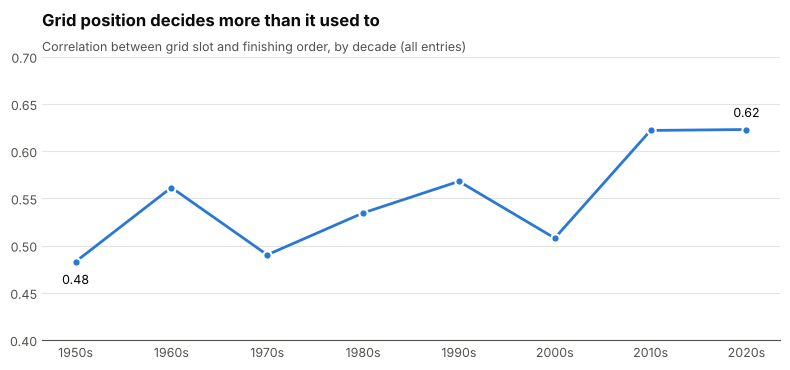

**Interpretation:** the grid–finish correlation rose from **0.48** in the 1950s to **0.62** in the 2020s. Pole sitters won **42%** of races in the 1950s and **52%** in the 2020s. Today the starting order holds to the finish more often, so qualifying matters more. One likely reason is reliability: far fewer cars break down than in early decades (this notebook does not test the cause).

In [23]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x, y = corr_pd["decade"], corr_pd["grid_finish_corr"]
ax.plot(x, y, color=BLUE, lw=2, marker="o", ms=6, markeredgecolor="white", markeredgewidth=1.5)
for i in [0, len(x) - 1]:
    ax.annotate(f"{y.iloc[i]:.2f}", (x.iloc[i], y.iloc[i]), xytext=(0, -16 if i == 0 else 9), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels([f"{d}s" for d in x]); ax.set_ylim(0.4, 0.7); ax.yaxis.grid(True, color=GRID, lw=0.8)
style(ax, "Grid position decides more than it used to", "Correlation between grid slot and finishing order, by decade (all entries)")
finish(fig, "fig1_corr_by_decade.png")
c0, c1 = corr_pd.iloc[0], corr_pd.iloc[-1]
display(Markdown(f"**Interpretation:** the grid–finish correlation rose from **{c0.grid_finish_corr:.2f}** in the 1950s to **{c1.grid_finish_corr:.2f}** in the 2020s. "
                 f"Pole sitters won **{c0.pole_win_rate:.0%}** of races in the 1950s and **{c1.pole_win_rate:.0%}** in the 2020s. "
                 "Today the starting order holds to the finish more often, so qualifying matters more. One likely reason is reliability: far fewer cars break down than in early decades (this notebook does not test the cause)."))

### 6.2 Where in the race do places change?

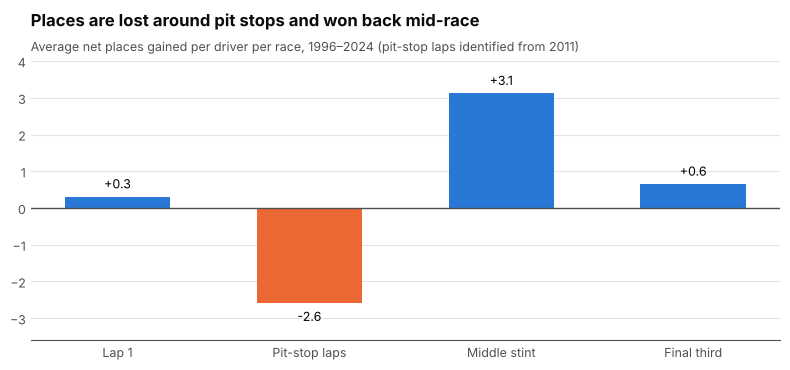

**Interpretation:** a driver loses a net **2.6** places on pit-stop laps and gains **3.1** in the middle stint, as others make their own stops. Lap 1 nets only **+0.3**, although positions swap a lot (**2.1** places changed per driver on average).

In [24]:
v = phase_pd["avg_net_gain"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(v.index, v.values, color=[BLUE if a >= 0 else ORANGE for a in v], width=0.55); ax.axhline(0, color=MUTED, lw=1)
for i, a in enumerate(v):
    ax.text(i, a + (0.15 if a >= 0 else -0.15), f"{a:+.1f}", ha="center", va="bottom" if a >= 0 else "top", fontsize=9)
ax.set_ylim(v.min() - 1, v.max() + 1); ax.yaxis.grid(True, color=GRID, lw=0.8)
style(ax, "Places are lost around pit stops and won back mid-race", "Average net places gained per driver per race, 1996–2024 (pit-stop laps identified from 2011)")
finish(fig, "fig2_phase_gains.png")
display(Markdown(f"**Interpretation:** a driver loses a net **{abs(v['Pit-stop laps']):.1f}** places on pit-stop laps and gains **{v['Middle stint']:.1f}** in the middle stint, "
                 f"as others make their own stops. Lap 1 nets only **{v['Lap 1']:+.1f}**, although positions swap a lot "
                 f"(**{phase_pd.loc['Lap 1', 'avg_places_changed']:.1f}** places changed per driver on average)."))

### 6.3 Which circuits are hardest to overtake at? (2010–2024)

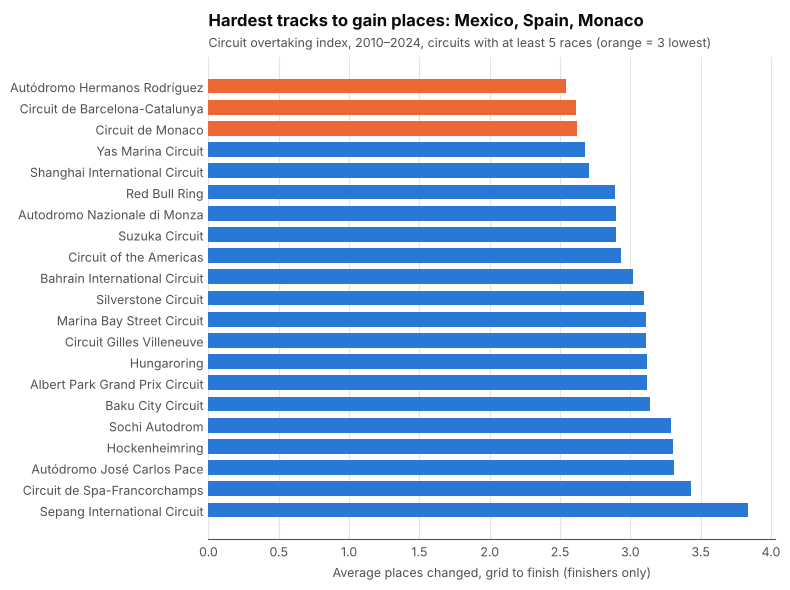

**Interpretation:** the hardest circuits to change places at are Autódromo Hermanos Rodríguez (2.54), Circuit de Barcelona-Catalunya (2.61), Circuit de Monaco (2.62); the easiest are Sepang International Circuit (3.84), Circuit de Spa-Francorchamps (3.43), Autódromo José Carlos Pace (3.31). Monaco and Barcelona match their reputation as hard places to pass.

In [25]:
o = oi_pd.sort_values("overtaking_index")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(o["circuit"], o["overtaking_index"], color=[ORANGE if i < 3 else BLUE for i in range(len(o))], height=0.7)
ax.invert_yaxis(); ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_xlabel("Average places changed, grid to finish (finishers only)", fontsize=9, color=MUTED)
style(ax, f"Hardest tracks to gain places: {', '.join(o['country'].head(3))}", "Circuit overtaking index, 2010–2024, circuits with at least 5 races (orange = 3 lowest)")
finish(fig, "fig3_overtaking_index.png")
lo, hi = o.head(3), o.tail(3).iloc[::-1]
display(Markdown("**Interpretation:** the hardest circuits to change places at are " + ", ".join(f"{r.circuit} ({r.overtaking_index:.2f})" for r in lo.itertuples()) +
                 "; the easiest are " + ", ".join(f"{r.circuit} ({r.overtaking_index:.2f})" for r in hi.itertuples()) +
                 ". Monaco and Barcelona match their reputation as hard places to pass."))

### 6.4 Which inputs does the model rely on?

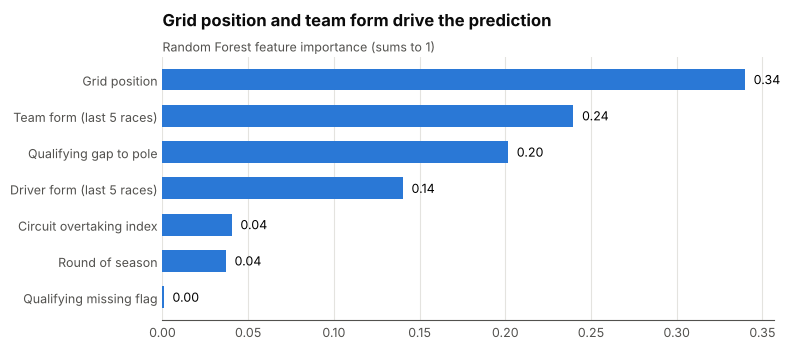

In [26]:
imp = pd.Series(rf.featureImportances.toArray(), index=FEATURES).sort_values()
names = {"grid_clean": "Grid position", "constructor_form5": "Team form (last 5 races)", "quali_gap_pct": "Qualifying gap to pole",
         "driver_form5": "Driver form (last 5 races)", "circuit_oi": "Circuit overtaking index", "round": "Round of season", "quali_missing": "Qualifying missing flag"}
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([names[k] for k in imp.index], imp.values, color=BLUE, height=0.6); ax.xaxis.grid(True, color=GRID, lw=0.8)
for i, a in enumerate(imp.values):
    ax.text(a + 0.005, i, f"{a:.2f}", va="center", fontsize=9)
style(ax, "Grid position and team form drive the prediction", "Random Forest feature importance (sums to 1)")
finish(fig, "fig4_feature_importance.png")

### 6.5 Predicted vs actual finishing position, 2023 season

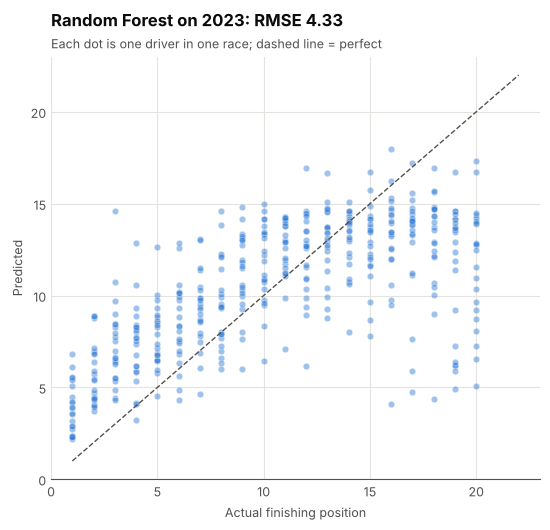

**Interpretation:** the Random Forest lowers RMSE from **5.15** (assume finish = grid) to **4.33**, a **16%** improvement. The largest errors are bottom-right: drivers predicted to finish well who retired, which pre-race data cannot foresee.

In [27]:
pp = rf_pred.select("label", "prediction").toPandas()
fig, ax = plt.subplots(figsize=(5.6, 5.4))
ax.plot([1, 22], [1, 22], ls="--", color=MUTED, lw=1)
ax.scatter(pp["label"], pp["prediction"], s=22, color=BLUE, alpha=0.45, edgecolors="white", linewidths=0.5)
ax.set_xlim(0, 23); ax.set_ylim(0, 23); ax.grid(True, color=GRID, lw=0.8)
ax.set_xlabel("Actual finishing position", fontsize=9, color=MUTED); ax.set_ylabel("Predicted", fontsize=9, color=MUTED)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color(MUTED)
r = results["Random Forest, pre-race (ours)"]
style(ax, f"Random Forest on 2023: RMSE {r['rmse']:.2f}", "Each dot is one driver in one race; dashed line = perfect")
finish(fig, "fig5_pred_vs_actual.png")
b = results["Baseline: finish = grid"]
display(Markdown(f"**Interpretation:** the Random Forest lowers RMSE from **{b['rmse']:.2f}** (assume finish = grid) to **{r['rmse']:.2f}**, "
                 f"a **{(1 - r['rmse'] / b['rmse']):.0%}** improvement. The largest errors are bottom-right: drivers predicted to finish well who retired, "
                 "which pre-race data cannot foresee."))

### 6.6 Comparison with the paper
The paper reports RMSE 2.87. To find out why our number differs, we re-ran the model with each of the paper's two choices applied: (1) using *laps completed*, which is only known after the race, and (2) removing drivers who did not finish.

In [28]:
PAPER_FEATURES = ["grid_clean", "laps", "constructorId", "round"]
dfp = df.withColumn("laps", F.col("laps").cast("double")).withColumn("constructorId", F.col("constructorId").cast("double"))
def rf_score(frame, cols):
    tr, te = split(frame, cols)
    return score(RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=200, maxDepth=8, seed=42).fit(tr).transform(te))

finishers = F.col("position").isNotNull()
cmp = {
    ("Baseline: finish = grid", "all"): results["Baseline: finish = grid"],
    ("Random Forest, pre-race (ours)", "all"): results["Random Forest, pre-race (ours)"],
    ("GBT, pre-race (ours)", "all"): results["GBT, pre-race (ours)"],
    ("Random Forest, paper's inputs incl. laps", "all"): rf_score(dfp, PAPER_FEATURES),
    ("Random Forest, pre-race (ours)", "finishers only"): rf_score(df.filter(finishers), FEATURES),
    ("Random Forest, paper's inputs incl. laps", "finishers only"): rf_score(dfp.filter(finishers), PAPER_FEATURES),
    ("TabNet (paper, reported)", "finishers only"): {"rmse": 2.87, "mae": 2.17, "r2": 0.75},
}
cmp_pd = pd.DataFrame(cmp).T; cmp_pd.index.names = ["model", "2023 test rows"]
cmp_pd

,,rmse,mae,r2
model,2023 test rows,,,
Baseline: finish = grid,all,5.147,3.698,0.203
"Random Forest, pre-race (ours)",all,4.327,3.355,0.437
"GBT, pre-race (ours)",all,4.666,3.587,0.345
"Random Forest, paper's inputs incl. laps",all,3.517,2.630,0.628
"Random Forest, pre-race (ours)",finishers only,3.223,2.451,0.612
"Random Forest, paper's inputs incl. laps",finishers only,3.288,2.519,0.596
"TabNet (paper, reported)",finishers only,2.870,2.170,0.750


In [29]:
ours_all = cmp[("Random Forest, pre-race (ours)", "all")]["rmse"]; laps_all = cmp[("Random Forest, paper's inputs incl. laps", "all")]["rmse"]
ours_fin = cmp[("Random Forest, pre-race (ours)", "finishers only")]["rmse"]; paper_fin = cmp[("Random Forest, paper's inputs incl. laps", "finishers only")]["rmse"]
display(Markdown(f"**Interpretation:** our pre-race model scores **{ours_all:.2f}** against the paper's **2.87**, but the setups are not the same. "
                 f"Adding the post-race *laps completed* input alone brings RMSE to **{laps_all:.2f}**. Removing non-finishers, as the paper did, brings our "
                 f"pre-race model to **{ours_fin:.2f}**, compared with **{paper_fin:.2f}** for the paper's inputs under the same conditions. "
                 f"The remaining gap of about **{ours_fin - 2.87:.1f}** places may come from TabNet with Optuna tuning and from the paper's unpublished data file; "
                 "we did not test those, so we make no claim about them. Differences in environment: the paper used one machine with pandas and PyTorch; "
                 "we used Spark MLlib tree ensembles."))

**Interpretation:** our pre-race model scores **4.33** against the paper's **2.87**, but the setups are not the same. Adding the post-race *laps completed* input alone brings RMSE to **3.52**. Removing non-finishers, as the paper did, brings our pre-race model to **3.22**, compared with **3.29** for the paper's inputs under the same conditions. The remaining gap of about **0.4** places may come from TabNet with Optuna tuning and from the paper's unpublished data file; we did not test those, so we make no claim about them. Differences in environment: the paper used one machine with pandas and PyTorch; we used Spark MLlib tree ensembles.

## 7. Performance evaluation and observations
**Test setup:** the environment printed in Section 0. Every timing below is the **median of 5 runs** after one warm-up run, so a single slow run doesn't skew it.

In [30]:
def median_time(fn, runs=5):
    fn(); ts = []
    for _ in range(runs):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return sorted(ts)[runs // 2]

perf = {}
agg = lambda d: d.groupBy("raceId", "driverId").agg(F.avg("milliseconds"), F.min("position"), F.max("position")).count()
N_LAPS = laps.count()

# 1. caching: same Spark SQL query on an uncached vs a cached table
res.unpersist(); perf["Overtaking-index query, table not cached"] = median_time(lambda: spark.sql(OI_SQL).collect())
res.cache().count(); perf["Overtaking-index query, table cached"] = median_time(lambda: spark.sql(OI_SQL).collect())

# 2. storage format: read + aggregate 589k lap rows from CSV vs Parquet
perf["Lap aggregation, read from CSV"] = median_time(lambda: agg(spark.read.csv(f"{DATA}/lap_times.csv", header=True, inferSchema=True, nullValue="\\N")))
if WRITE_PARQUET:
    perf["Lap aggregation, read from Parquet"] = median_time(lambda: agg(spark.read.parquet(pq_laps)))

# 3. partitions: same aggregation on cached data split into 1/2/4/8 partitions
for p in [1, 2, 4, 8]:
    lpart = laps.repartition(p).cache(); lpart.count()
    perf[f"Lap aggregation, cached, {p} partition(s)"] = median_time(lambda: agg(lpart)); lpart.unpersist()

# 4. single-machine baseline: pandas doing the same read + aggregation
def pandas_agg():
    pdf = pd.read_csv(f"{DATA}/lap_times.csv", na_values="\\N")
    return len(pdf.groupby(["raceId", "driverId"]).agg({"milliseconds": "mean", "position": ["min", "max"]}))
perf["Lap aggregation, pandas baseline (read from CSV)"] = median_time(pandas_agg)

perf_pd = pd.DataFrame({"median seconds": pd.Series(perf).round(3)})
perf_pd["throughput (lap rows/s)"] = [f"{N_LAPS / s:,.0f}" if "Lap" in k else "–" for k, s in perf.items()]
perf_pd

,median seconds,throughput (lap rows/s)
"Overtaking-index query, table not cached",0.793,–
"Overtaking-index query, table cached",0.346,–
"Lap aggregation, read from CSV",1.074,"548,317"
"Lap aggregation, read from Parquet",0.222,"2,648,255"
"Lap aggregation, cached, 1 partition(s)",0.062,"9,477,285"
"Lap aggregation, cached, 2 partition(s)",0.111,"5,323,092"
"Lap aggregation, cached, 4 partition(s)",0.142,"4,158,335"
"Lap aggregation, cached, 8 partition(s)",0.172,"3,432,985"
"Lap aggregation, pandas baseline (read from CSV)",0.240,"2,452,631"


### 7.1 Correctness checks

In [31]:
checks = []
spark_groups = agg(laps); pandas_groups = pandas_agg()
checks.append(("Lap aggregation: Spark groups = pandas groups", f"{spark_groups:,} vs {pandas_groups:,}", spark_groups == pandas_groups))

oi_df_api = (res.filter("finished = 1 AND year >= 2010 AND grid > 0").groupBy("circuit", "country")
                .agg(F.avg(F.abs("positions_gained")).alias("overtaking_index"), F.countDistinct("raceId").alias("races"))
                .filter("races >= 5").toPandas().set_index("circuit").sort_index())
same = np.allclose(oi_df_api["overtaking_index"], oi_pd.set_index("circuit").sort_index()["overtaking_index"])
checks.append(("Overtaking index: Spark SQL = DataFrame API", f"{len(oi_df_api)} circuits", same))

# independent check of the 2020s correlation in plain pandas, from the raw CSVs
r = pd.read_csv(f"{DATA}/results.csv", na_values="\\N").merge(pd.read_csv(f"{DATA}/races.csv")[["raceId", "year"]], on="raceId")
r = r[r.year >= 2020].sort_values("positionOrder").drop_duplicates(["raceId", "driverId"])
r["g"] = r.grid.where(r.grid > 0, r.groupby("raceId").grid.transform("max") + 1)
pandas_corr, spark_corr = r.g.corr(r.positionOrder), corr_pd.iloc[-1].grid_finish_corr
checks.append(("2020s grid-finish correlation: pandas = Spark", f"{pandas_corr:.4f} vs {spark_corr:.4f}", abs(pandas_corr - spark_corr) < 1e-6))

pos_sum = per.groupBy("raceId", "driverId").agg(F.sum("gain").alias("g")).join(
    lp.groupBy("raceId", "driverId").agg(F.max("lap").alias("last")), ["raceId", "driverId"]).join(
    lp.select("raceId", "driverId", "lap", "pos", "grid_clean"), ["raceId", "driverId"]).filter("lap = last")
bad = pos_sum.filter(F.col("g") != F.col("grid_clean") - F.col("pos")).count()
checks.append(("Phase gains add up: sum of lap deltas = grid - last-lap position", f"{bad} mismatches", bad == 0))
pd.DataFrame(checks, columns=["check", "values", "passed"])

,check,values,passed
0,Lap aggregation: Spark groups = pandas groups,"11,041 vs 11,041",True
1,Overtaking index: Spark SQL = DataFrame API,21 circuits,True
2,2020s grid-finish correlation: pandas = Spark,0.6229 vs 0.6229,True
3,Phase gains add up: sum of lap deltas = grid -...,0 mismatches,True


In [32]:
c, u = perf["Overtaking-index query, table cached"], perf["Overtaking-index query, table not cached"]
p1, p8 = perf["Lap aggregation, cached, 1 partition(s)"], perf["Lap aggregation, cached, 8 partition(s)"]
sp, pdt = perf["Lap aggregation, read from CSV"], perf["Lap aggregation, pandas baseline (read from CSV)"]
txt = (f"**Observations:** caching made the Spark SQL query **{u / c:.1f}x** faster. "
       f"Splitting the lap data into more partitions made it slower here ({p1:.3f} s with 1 vs {p8:.3f} s with 8), and pandas was **{sp / pdt:.1f}x** faster than Spark. "
       f"At this size ({N_LAPS:,} rows, a few MB in memory, {spark.sparkContext.defaultParallelism} cores), Spark's task scheduling costs more than parallelism saves. ")
if WRITE_PARQUET:
    pqt = perf["Lap aggregation, read from Parquet"]
    txt += f"Reading Parquet instead of CSV made the same job **{sp / pqt:.1f}x** faster, because Parquet is columnar and already typed. "
txt += ("Spark's value here is that the same code runs unchanged on larger data and on a cluster, not speed at this size. "
        f"Model training took {train_time['Random Forest']:.0f} s (Random Forest) and {train_time['GBT']:.0f} s (GBT); GBT was slower and less accurate.")
display(Markdown(txt))

**Observations:** caching made the Spark SQL query **2.3x** faster. Splitting the lap data into more partitions made it slower here (0.062 s with 1 vs 0.172 s with 8), and pandas was **4.5x** faster than Spark. At this size (589,081 rows, a few MB in memory, 2 cores), Spark's task scheduling costs more than parallelism saves. Reading Parquet instead of CSV made the same job **4.8x** faster, because Parquet is columnar and already typed. Spark's value here is that the same code runs unchanged on larger data and on a cluster, not speed at this size. Model training took 9 s (Random Forest) and 29 s (GBT); GBT was slower and less accurate.

**Limitations:**
- Single machine only, so no true cluster speed-up could be measured.
- Retirements can't be predicted from pre-race data.
- Lap data starts in 1996 and pit-stop data in 2011.
- The paper's exact data file is not published.

**Improvements:**
- Add OpenF1 car telemetry and weather (2023 onwards) to reach real Big Data volume.
- Run on a multi-node HDFS/YARN cluster and measure speed-up.
- Tune the MLlib models with cross-validation.

## 8. Tools, responsible use and references

In [33]:
pd.DataFrame([
    ("Language", f"Python {platform.python_version()}"),
    ("Big Data framework", f"Apache Spark {spark.version} (PySpark DataFrames, Spark SQL, window functions, MLlib), local mode"),
    ("Storage", "CSV (raw), Apache Parquet partitioned by decade (clean)"),
    ("Visualization", f"Matplotlib {matplotlib.__version__}, pandas {pd.__version__} tables, Jupyter notebook"),
    ("Computing resources", f"{spark.sparkContext.defaultParallelism} CPU cores, Java {spark.sparkContext._jvm.System.getProperty('java.version')}"),
    ("Version control", "Git / GitHub"),
], columns=["", "used"]).set_index("")

,used
,
Language,Python 3.13.18
Big Data framework,"Apache Spark 4.3.0 (PySpark DataFrames, Spark ..."
Storage,"CSV (raw), Apache Parquet partitioned by decad..."
Visualization,"Matplotlib 3.11.2, pandas 2.3.3 tables, Jupyte..."
Computing resources,"2 CPU cores, Java 21.0.12.1"
Version control,Git / GitHub


**Responsible use:**
- **Permissions:** a public Kaggle dataset built from the open Ergast/Jolpica database, used for academic, non-commercial work under its listed licence. The CSVs are not redistributed with the code.
- **Privacy:** the data holds only public sporting results and professional drivers' names. There is no personal or sensitive data, and nobody is profiled beyond public race results.
- **Security:** files are stored locally and no credentials or API keys are needed.
- **Honesty:** only results measured in this notebook are reported.

**References**
1. Urdhwareshe, A. (2025). *The Use of Machine Learning in Predicting Formula 1 Race Outcomes.* Preprints.org. DOI: [10.20944/preprints202504.1471.v1](https://www.preprints.org/manuscript/202504.1471) (selected paper)
2. Rao, R. *Formula 1 World Championship (1950–2024)*, Kaggle dataset and documentation: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020
3. Weissbock, J. & Mills, S. (2025). *Evaluating the Predictive Power of Qualifying Performance in Formula One Grand Prix.* arXiv:2507.10966. https://arxiv.org/abs/2507.10966
4. Apache Spark MLlib Guide: https://spark.apache.org/docs/latest/ml-guide.html
5. Apache Parquet documentation: https://parquet.apache.org/docs/

## Appendix A. What we changed during development and why

| # | First version | Problem found | Change |
| --- | --- | --- | --- |
| 1 | Overtaking index over all seasons, 1950–2024 | Old circuits came out on top (Indianapolis 7.5, Zolder 6.9) because early races had 30+ cars and frequent breakdowns, not because overtaking was easy | Restricted to 2010–2024 and circuits with at least 5 races (Section 5.3) |
| 2 | Duplicate (race, driver) rows dropped arbitrarily | They are real shared drives (1950–1978): one driver in two cars | Keep the entry with the better finish (Section 4.4) |
| 3 | Each performance test timed once | The same test varied noticeably between runs (e.g. 0.26 s vs 0.44 s for one aggregation) | Median of 5 runs after a warm-up (Section 7) |
| 4 | Our RMSE (4.33) compared directly with the paper's 2.87 | The setups were not the same | Re-ran with the paper's inputs and filters to explain the gap (Section 6.6) |
| 5 | Correlation chart labelled "classified entries" | The calculation includes retirements | Label corrected to "all entries" |
| 6 | Spark read CSVs only | Point 5 asks about storage, and the first version had no storage layer | Added Parquet storage partitioned by decade, and measured CSV vs Parquet (Sections 5.1, 7) |
| 7 | Analysis used the DataFrame API only | Spark SQL was not shown | Correlation and overtaking index rewritten as Spark SQL queries, and checked against the DataFrame API (Sections 5.2, 5.3, 7.1) |

## Appendix B. How to reproduce
1. Install Python 3.10+, Java 17 or 21, then `pip install pyspark pandas matplotlib jupyter`.
2. Download the Kaggle dataset and unzip the 14 CSVs into `data/` next to this notebook.
3. Open the notebook in Jupyter (or Google Colab) and choose **Run All**. A full run takes about 6 minutes on 2 cores.
4. On Windows without Hadoop `winutils`, set the environment variable `F1_PARQUET=0` to skip the Parquet steps.

In [34]:
spark.stop()